# Modelling

This notebook compares four algorithms (logistic regression, Gaussian Naive Bayes, KNN and a
decision tree), tunes each one, chooses a decision threshold and the final model, and writes
the Kaggle submission. Every model uses the preparation and feature set chosen in the
preprocessing notebook (`prepare_selected` in `preprocessing.py`) and is measured on the same
5 time-based splits against the same reference. A difference only counts when it is larger
than 2 × SEM.

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score)

# the final preparation and the evaluation tools, shared with the preprocessing notebook
from preprocessing import (DATE, ENCODER_FINAL, SCALER_FINAL, TARGET, compare, evaluate, fit_predict,
                           load_train, prepare_selected, sem, time_splits, verdict)

## 1. Data, splits and the reference

The data and the 5 time-based splits are the same as in the preprocessing notebook: the
training set sorted by date, without the 65 rows that have no date, and each split trains on
the past and validates on what comes next. The reference is the default logistic regression
on the final feature set (F1 0.7508, accuracy 0.7163). If `preprocessing.py` changes by
accident, the check below stops the notebook; the tolerance of 0.001 allows for the fourth
decimal changing on another computer.

Each model is measured on the training and validation rows side by side. A training F1 far
above the validation F1 means overfitting, and two low, close values mean underfitting. The
share of predictions equal to 1 is always shown too, because the preprocessing notebook
showed that F1 rises just by predicting 1 more often. The reference has a training F1 of
0.7316, below its validation F1, so it shows no sign of overfitting, and a more flexible
model may get more out of the data.

In [2]:
raw, frame = load_train("../data/train.csv")
splits = time_splits(frame)
test_csv = pd.read_csv("../data/test.csv", index_col="ID")

print(f"train: {len(frame):,} purchases ({len(raw) - len(frame)} without a date left out);"
      f" test: {len(test_csv):,} purchases")
for fold, (train_idx, val_idx) in enumerate(splits, start=1):
    print(f"split {fold}: trains on {len(train_idx):,}, validates on {len(val_idx):,}")

train: 6,469 purchases (65 without a date left out); test: 986 purchases
split 1: trains on 1,079, validates on 1,078
split 2: trains on 2,157, validates on 1,078
split 3: trains on 3,235, validates on 1,078
split 4: trains on 4,313, validates on 1,078
split 5: trains on 5,391, validates on 1,078


In [3]:
# the imported preparation must give the result of the preprocessing notebook
selected_run = evaluate(prepare_selected, frame, splits, scaler=SCALER_FINAL,
                        encoder=ENCODER_FINAL)
assert abs(selected_run["f1"].mean() - 0.7508) < 0.001
assert abs(selected_run["accuracy"].mean() - 0.7163) < 0.001
print(f"reference (logistic regression, final preparation): F1 {selected_run['f1'].mean():.4f}"
      f" +- {sem(selected_run['f1']):.4f}, accuracy {selected_run['accuracy'].mean():.4f}")

reference (logistic regression, final preparation): F1 0.7508 +- 0.0074, accuracy 0.7163


In [4]:
def run_model(model, threshold=None):
    """On each split: validation F1 and accuracy, training F1 and % of predictions equal to 1.

    `model=None` is the reference logistic regression; `threshold=None` uses 0.5.
    """
    rows = []
    for train_idx, val_idx in splits:
        train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
        predicted = fit_predict(prepare_selected, train, valid, SCALER_FINAL, ENCODER_FINAL,
                                model, None, threshold)
        on_train = fit_predict(prepare_selected, train, train, SCALER_FINAL, ENCODER_FINAL,
                               model, None, threshold)
        rows.append({"f1": f1_score(valid[TARGET], predicted),
                     "accuracy": accuracy_score(valid[TARGET], predicted),
                     "train f1": f1_score(train[TARGET], on_train),
                     "% predicted 1": 100 * predicted.mean()})
    return pd.DataFrame(rows)


def sweep(models, threshold=None):
    """Each model against the reference, on the same 5 splits, with the 2 x SEM rule."""
    runs = {name: run_model(model, threshold) for name, model in models.items()}
    table = compare(runs, reference, metric="f1").astype({"f1": float, "accuracy": float,
                                                           "vs base": float, "SEM": float})
    table["2 x SEM"] = 2 * table["SEM"]
    table["verdict"] = verdict(table)
    table["train F1"] = [runs[name]["train f1"].mean() for name in table.index]
    table["train - validation"] = table["train F1"] - table["f1"]
    table["% predicted 1"] = [runs[name]["% predicted 1"].mean() for name in table.index]
    shown = ["f1", "vs base", "2 x SEM", "better on", "verdict", "train F1",
             "train - validation", "accuracy", "% predicted 1"]
    return table[shown], runs


reference = run_model(None)
assert (reference["f1"] == selected_run["f1"]).all()   # the same ruler as evaluate
check, _ = sweep({"logistic regression (reference)": None})
print(check.round(4).to_string())

                                     f1  vs base  2 x SEM better on verdict  train F1  train - validation  accuracy  % predicted 1
logistic regression (reference)  0.7508      0.0      0.0    0 of 5     tie    0.7316             -0.0192    0.7163         57.885


## 2. Evaluation strategy and metric

We validate with 5 time-based splits (`TimeSeriesSplit`). `test.csv` is later than the
training data, so the real question is predicting the future from the past, and each split
does exactly that. 94.5% of the test purchases belong to customers already in the training
data, so the model predicts customers it knows, always at later dates. A holdout or a random
K-Fold would put future purchases in training and validate on the past, which gives better
results than the real ones. Five splits instead of one give a mean and a standard error, and
differences are compared split by split. One known limitation is that there is no gap between
training and validation, so the target of a late training purchase can look 90 days into the
validation period. `test.csv` is never used to choose anything, only for the final prediction.

The metric is F1, with accuracy always shown beside it. F1 combines the precision and recall
of class 1, the purchase that is followed by another one, so it is only high when the model
finds the customers who come back without filling the list with false alarms. That is the
class the company cares about: the project brief wants to predict repeat purchases for "more
targeted commercial actions". F1 is also the Kaggle metric. Its limit is that when the
positive class is the majority, always predicting 1 already scores well. Here 56% of
purchases are repeated, always predicting 1 gives F1 0.721, and the reference beats it by
only +0.030 in F1 but +0.153 in accuracy (0.564 to 0.716). Accuracy shows that the model
learned something, which F1 alone almost hides. The reference balances precision (0.744) and
recall (0.761), and its errors split into 805 false alarms and 724 missed repeat purchases.

In [5]:
# precision: of the purchases the model says will repeat, how many do;
# recall: of the purchases that repeat, how many the model finds
metric_rows = []
for fold, (train_idx, val_idx) in enumerate(splits, start=1):
    train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
    truth = valid[TARGET]
    for name, predicted in [("reference", fit_predict(prepare_selected, train, valid,
                                                      SCALER_FINAL, ENCODER_FINAL)),
                            ("always predict 1", np.ones(len(valid), dtype=int))]:
        metric_rows.append({"split": fold, "prediction": name,
                            "precision": precision_score(truth, predicted),
                            "recall": recall_score(truth, predicted),
                            "f1": f1_score(truth, predicted),
                            "accuracy": accuracy_score(truth, predicted),
                            "% actual 1": 100 * truth.mean()})
metrics = pd.DataFrame(metric_rows)
shown = ["precision", "recall", "f1", "accuracy"]
print("reference, split by split:")
print(metrics[metrics["prediction"] == "reference"].set_index("split")[shown + ["% actual 1"]]
      .round(4).to_string(), "\n")
print("mean of the 5 splits:")
print(metrics.groupby("prediction")[shown].mean().round(4).to_string())

reference, split by split:
       precision  recall      f1  accuracy  % actual 1
split                                                 
1         0.7008  0.8365  0.7627    0.6957     58.4416
2         0.7178  0.7639  0.7401    0.7134     53.4323
3         0.7791  0.7327  0.7552    0.7263     57.6067
4         0.7359  0.7201  0.7279    0.7199     52.0408
5         0.7862  0.7512  0.7683    0.7263     60.3896 

mean of the 5 splits:
                  precision  recall      f1  accuracy
prediction                                           
always predict 1     0.5638  1.0000  0.7206    0.5638
reference            0.7439  0.7609  0.7508    0.7163


In [6]:
# confusion matrix of the reference, summed over the 5 validation sets: [[TN FP] [FN TP]]
matrix = sum(confusion_matrix(frame[TARGET].iloc[val_idx],
                              fit_predict(prepare_selected, frame.iloc[train_idx],
                                          frame.iloc[val_idx], SCALER_FINAL, ENCODER_FINAL))
             for train_idx, val_idx in splits)
matrix_table = pd.DataFrame(matrix, index=["actual 0 (no repeat)", "actual 1 (repeat)"],
                            columns=["predicted 0", "predicted 1"])
print(matrix_table.to_string(), "\n")
(tn, fp), (fn, tp) = matrix
print(f"{tn + fp + fn + tp:,} validation purchases; correct {tn + tp:,}"
      f" ({100 * (tn + tp) / matrix.sum():.1f}%)")
print(f"false alarms (FP): {fp:,}, {100 * fp / (tn + fp):.1f}% of the purchases without a repeat")
print(f"missed (FN): {fn:,}, {100 * fn / (fn + tp):.1f}% of the purchases with a repeat")

                      predicted 0  predicted 1
actual 0 (no repeat)         1546          805
actual 1 (repeat)             724         2315 

5,390 validation purchases; correct 3,861 (71.6%)
false alarms (FP): 805, 34.2% of the purchases without a repeat
missed (FN): 724, 23.8% of the purchases with a repeat


## 3. Logistic regression

We change one setting at a time against the reference: the strength `C` for each penalty
(L2, L1 and elastic net), no penalty (`C=np.inf`), `class_weight` and `fit_intercept`. Every
model uses `max_iter=5000`, and the `saga` solver (L1 and elastic net) also gets a
`random_state`, because it goes through the rows in random order. The grid then combines
only the values that did not get worse; the full grid of 76 combinations would take more
than 10 minutes, because `saga` is slow. No penalty is a separate sub-grid, since it has no
strength or penalty type to choose.

Strong penalties (C ≤ 0.1) get worse or come close to predicting 1 every time. From C=1 up,
the three penalty types are close to each other, and only L1 with C=10 and C=100 passes
2 × SEM. No penalty and `fit_intercept=False` tie. `class_weight="balanced"` is worse
(−0.0126): class 1 is the majority here, so it predicts fewer 1s (52% against 58%) and loses
recall. No setting overfits; the training F1 always stays below the validation F1.

The top of the grid holds four L1 combinations with C=10 or 100 that tie with each other. We
keep the one with the highest mean F1: L1, C=100, without an intercept, with F1 0.7540
(+0.0031 against the reference, 2 × SEM = 0.0028, better on 5 of 5) and accuracy 0.7219. It
was chosen among 24 combinations on the same splits that measure it, so the gain is
optimistic.

In [7]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

from preprocessing import RANDOM_STATE

# C (the inverse of the penalty strength) for each penalty type; C=1 with L2 is the default
c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
penalties = {"L2": LogisticRegression(max_iter=5000),
             "L1": LogisticRegression(solver="saga", l1_ratio=1.0, max_iter=5000,
                                      random_state=RANDOM_STATE),
             "elastic net": LogisticRegression(solver="saga", l1_ratio=0.5, max_iter=5000,
                                               random_state=RANDOM_STATE)}
c_table, c_runs = sweep({f"{family}, C={value:g}": clone(model).set_params(C=value)
                         for family, model in penalties.items() for value in c_values})
c_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
"L2, C=0.001",0.7367,-0.0141,0.0203,1 of 5,tie,0.7169,-0.0198,0.6191,87.9035
"L2, C=0.01",0.7394,-0.0114,0.0105,1 of 5,worse,0.7170,-0.0224,0.6850,65.1020
"L2, C=0.1",0.7485,-0.0023,0.0072,1 of 5,tie,0.7236,-0.0250,0.7087,59.9814
"L2, C=1",0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850
"L2, C=10",0.7499,-0.0010,0.0034,2 of 5,tie,0.7310,-0.0188,0.7145,58.1447
"L2, C=100",0.7478,-0.0031,0.0051,2 of 5,tie,0.7304,-0.0174,0.7122,58.2189
"L1, C=0.001",0.7206,-0.0303,0.0113,0 of 5,worse,0.7119,-0.0087,0.5638,100.0000
"L1, C=0.01",0.7126,-0.0383,0.0117,0 of 5,worse,0.7003,-0.0123,0.6284,73.7291
"L1, C=0.1",0.7427,-0.0082,0.0053,1 of 5,worse,0.7153,-0.0274,0.7032,59.3878
"L1, C=1",0.7523,0.0015,0.0022,4 of 5,tie,0.7310,-0.0212,0.7195,57.2356


In [8]:
# no penalty (C=np.inf) against the default penalty (C=1)
none_table, none_runs = sweep({"L2, C=1": LogisticRegression(C=1.0, max_iter=5000),
                               "no penalty, C=inf": LogisticRegression(C=np.inf,
                                                                       max_iter=5000)})
none_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
"L2, C=1",0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850
"no penalty, C=inf",0.7456,-0.0053,0.0065,2 of 5,tie,0.7313,-0.0142,0.7096,58.2189


In [9]:
# "balanced" weights each class by the inverse of its frequency; class 1 is the majority here,
# so we expect fewer predictions of 1, less recall and less F1
weight_table, weight_runs = sweep({
    f"class_weight={weight}": LogisticRegression(class_weight=weight, max_iter=5000)
    for weight in [None, "balanced"]})
weight_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
class_weight=None,0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850
class_weight=balanced,0.7382,-0.0126,0.0089,1 of 5,worse,0.7153,-0.0229,0.7178,52.0965


In [10]:
# without an intercept, a purchase with every column at zero is forced to probability 0.5
intercept_table, intercept_runs = sweep({
    f"fit_intercept={value}": LogisticRegression(fit_intercept=value, max_iter=5000)
    for value in [True, False]})
intercept_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
fit_intercept=True,0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850
fit_intercept=False,0.7515,0.0007,0.0023,3 of 5,tie,0.7316,-0.0199,0.7167,58.0334


In [11]:
# the grid, only with the values that did not get worse ("tie" or "better")
def kept(table, values, label):
    """The values whose row `label(value)` in the table did not get worse."""
    return [value for value in values if table.loc[label(value), "verdict"] != "worse"]


grid_c = {family: kept(c_table, c_values, lambda value, f=family: f"{f}, C={value:g}")
          for family in penalties}
grid_weight = kept(weight_table, [None, "balanced"], lambda value: f"class_weight={value}")
grid_intercept = kept(intercept_table, [True, False], lambda value: f"fit_intercept={value}")
grid_none = none_table.loc["no penalty, C=inf", "verdict"] != "worse"

grid = {}
for family, model in penalties.items():
    for value in grid_c[family]:
        for weight in grid_weight:
            for intercept in grid_intercept:
                grid[f"{family}, C={value:g}, class_weight={weight}, fit_intercept={intercept}"] = \
                    clone(model).set_params(C=value, class_weight=weight, fit_intercept=intercept)
if grid_none:
    for weight in grid_weight:
        for intercept in grid_intercept:
            grid[f"no penalty, class_weight={weight}, fit_intercept={intercept}"] = \
                LogisticRegression(C=np.inf, class_weight=weight, fit_intercept=intercept,
                                   max_iter=5000)
print("values kept in the grid:", {"C": grid_c, "class_weight": grid_weight,
                                   "fit_intercept": grid_intercept, "C=inf": grid_none})
print(f"{len(grid)} combinations (the full grid has 76)\n")

grid_table, grid_runs = sweep(grid)
print("the 5 best by mean F1, and the default model:")
default_name = "L2, C=1, class_weight=None, fit_intercept=True"
top = grid_table.sort_values("f1", ascending=False).head(5)
if default_name in grid_table.index and default_name not in top.index:
    top = pd.concat([top, grid_table.loc[[default_name]]])
top.round(4)

values kept in the grid: {'C': {'L2': [0.001, 0.1, 1.0, 10.0, 100.0], 'L1': [1.0, 10.0, 100.0], 'elastic net': [1.0, 10.0, 100.0]}, 'class_weight': [None], 'fit_intercept': [True, False], 'C=inf': True}
24 combinations (the full grid has 76)



the 5 best by mean F1, and the default model:


,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
"L1, C=100, class_weight=None, fit_intercept=False",0.7540,0.0031,0.0028,5 of 5,better,0.7309,-0.0231,0.7219,57.1429
"L1, C=100, class_weight=None, fit_intercept=True",0.7538,0.0029,0.0025,5 of 5,better,0.7309,-0.0228,0.7217,57.1243
"L1, C=10, class_weight=None, fit_intercept=False",0.7535,0.0027,0.0019,5 of 5,better,0.7304,-0.0231,0.7215,57.0315
"L1, C=10, class_weight=None, fit_intercept=True",0.7535,0.0027,0.0019,5 of 5,better,0.7304,-0.0231,0.7215,57.0315
"elastic net, C=10, class_weight=None, fit_intercept=True",0.7524,0.0016,0.0018,4 of 5,tie,0.7310,-0.0214,0.7199,57.2356
"L2, C=1, class_weight=None, fit_intercept=True",0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850


In [12]:
# the combination with the highest mean F1
logistic_chosen_name = grid_table["f1"].idxmax()
BEST_LOGISTIC = clone(grid[logistic_chosen_name])   # for the threshold and the final model
logistic_runs = grid_runs[logistic_chosen_name]
print(f"best logistic regression: {logistic_chosen_name}")
print(grid_table.loc[[logistic_chosen_name]].round(4).to_string())

best logistic regression: L1, C=100, class_weight=None, fit_intercept=False
                                                      f1  vs base  2 x SEM better on verdict  train F1  train - validation  accuracy  % predicted 1
L1, C=100, class_weight=None, fit_intercept=False  0.754   0.0031   0.0028    5 of 5  better    0.7309             -0.0231    0.7219        57.1429


## 4. Gaussian Naive Bayes

Naive Bayes assumes that, within each class, the columns are independent and normally
distributed. They are not here (there are 0/1 one-hot columns and correlated counts), so it
may stay below the logistic regression. It is very fast, because it only computes means and
variances per class. We test `var_smoothing`, which adds a fraction of the largest variance
to every variance so that none is zero, the class `priors`, and calibration with
`CalibratedClassifierCV`, which learns to correct the probabilities on parts of each training
split. The full grid has 105 combinations, and accuracy is shown beside F1, because a prior
that only makes the model predict more 1s raises F1 without getting more right.

The default model is much worse than the logistic regression (F1 0.538, accuracy 0.588), and
its training F1 (0.42) is even lower: it underfits because its assumptions fail here.
`var_smoothing` helps up to 1, and at 10 the model falls back to predicting 1 almost always
(95%). The priors alone barely change anything, and calibration helps most (isotonic: F1
0.718).

We keep the combination with the highest mean F1: `var_smoothing=1`, priors [0.2, 0.8], no
calibration, with F1 0.7390. That F1 comes from predicting 1 for 89% of purchases, and its
accuracy drops to 0.6212 (−0.0952 against the reference, worse). It only ties with the
reference in F1 because it varies a lot between splits (2 × SEM = 0.0163, better on 1 of 5).
It does not reach the logistic regression, so it enters the final table as a different
algorithm, not as a candidate for the final model.

In [13]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB

nb_default_table, nb_default_runs = sweep({"GaussianNB()": GaussianNB()})
nb_default_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
GaussianNB(),0.5382,-0.2126,0.1509,0 of 5,worse,0.416,-0.1222,0.5878,43.9889


In [14]:
# var_smoothing: nothing changes while it is small; when it reaches the size of the
# variances, the model falls back to the prior
smoothing_values = [1e-12, 1e-9, 1e-6, 1e-3, 1e-1, 1.0, 10.0]
smoothing_table, smoothing_runs = sweep({f"var_smoothing={value:g}": GaussianNB(var_smoothing=value)
                                         for value in smoothing_values})
smoothing_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
var_smoothing=1e-12,0.4968,-0.2540,0.1825,0 of 5,worse,0.3805,-0.1164,0.5623,43.8590
var_smoothing=1e-09,0.5382,-0.2126,0.1509,0 of 5,worse,0.4160,-0.1222,0.5878,43.9889
var_smoothing=1e-06,0.6108,-0.1401,0.1177,0 of 5,worse,0.4997,-0.1111,0.6423,42.8015
var_smoothing=0.001,0.6747,-0.0762,0.0320,0 of 5,worse,0.6343,-0.0403,0.6772,43.7662
var_smoothing=0.1,0.6856,-0.0652,0.0217,0 of 5,worse,0.6661,-0.0195,0.6755,47.6067
var_smoothing=1,0.7077,-0.0431,0.0186,0 of 5,worse,0.6856,-0.0222,0.6787,54.2301
var_smoothing=10,0.7281,-0.0227,0.0186,1 of 5,worse,0.7112,-0.0169,0.5878,95.1577


In [15]:
# priors in the order [class 0, class 1]; None uses the training frequency (about 44% / 56%)
prior_values = [None, [0.8, 0.2], [0.6, 0.4], [0.5, 0.5], [0.2, 0.8]]
prior_table, prior_runs = sweep({f"priors={prior}": GaussianNB(priors=prior)
                                 for prior in prior_values})
prior_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
priors=None,0.5382,-0.2126,0.1509,0 of 5,worse,0.4160,-0.1222,0.5878,43.9889
"priors=[0.8, 0.2]",0.5212,-0.2296,0.1748,0 of 5,worse,0.4021,-0.1191,0.5909,40.7792
"priors=[0.6, 0.4]",0.5310,-0.2199,0.1595,0 of 5,worse,0.4112,-0.1198,0.5878,42.8757
"priors=[0.5, 0.5]",0.5378,-0.2130,0.1527,0 of 5,worse,0.4155,-0.1223,0.5889,43.7291
"priors=[0.2, 0.8]",0.5556,-0.1952,0.1342,0 of 5,worse,0.4300,-0.1256,0.5907,46.0668


In [16]:
# calibration: the internal parts come only from each training split, so validation never enters
def naive_bayes(var_smoothing=1e-9, priors=None, method=None):
    """GaussianNB with these settings; with `method`, calibrated."""
    model = GaussianNB(var_smoothing=var_smoothing, priors=priors)
    if method is None:
        return model
    return CalibratedClassifierCV(model, method=method)


calibration_values = [None, "sigmoid", "isotonic"]
calibration_table, calibration_runs = sweep({f"calibration={method}": naive_bayes(method=method)
                                             for method in calibration_values})
calibration_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
calibration=None,0.5382,-0.2126,0.1509,0 of 5,worse,0.4160,-0.1222,0.5878,43.9889
calibration=sigmoid,0.7105,-0.0404,0.0293,0 of 5,worse,0.6978,-0.0126,0.6104,80.0557
calibration=isotonic,0.7178,-0.0331,0.0100,0 of 5,worse,0.7093,-0.0084,0.6855,55.5102


In [17]:
# the full grid: 7 var_smoothing x 5 priors x 3 calibrations, with the accuracy verdict beside
nb_grid = {f"var_smoothing={value:g}, priors={prior}, calibration={method}":
           naive_bayes(value, prior, method)
           for value in smoothing_values for prior in prior_values for method in calibration_values}
nb_grid_table, nb_grid_runs = sweep(nb_grid)
accuracy_check = compare(nb_grid_runs, reference, metric="accuracy").astype(
    {"accuracy": float, "vs base": float, "SEM": float})
nb_grid_table["accuracy vs base"] = accuracy_check["vs base"]
nb_grid_table["accuracy verdict"] = verdict(accuracy_check)

print(f"{len(nb_grid)} combinations; the 5 best by mean F1, and the default Naive Bayes:")
nb_default_name = "var_smoothing=1e-09, priors=None, calibration=None"
nb_top = nb_grid_table.sort_values("f1", ascending=False).head(5)
nb_top = pd.concat([nb_top, nb_grid_table.loc[[nb_default_name]]])
nb_top.round(4)

105 combinations; the 5 best by mean F1, and the default Naive Bayes:


,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1,accuracy vs base,accuracy verdict
"var_smoothing=1, priors=[0.2, 0.8], calibration=None",0.7390,-0.0119,0.0163,1 of 5,tie,0.7175,-0.0215,0.6212,88.9981,-0.0952,worse
"var_smoothing=1e-09, priors=[0.8, 0.2], calibration=sigmoid",0.7351,-0.0157,0.0180,2 of 5,tie,0.7199,-0.0152,0.6239,85.1206,-0.0924,worse
"var_smoothing=1, priors=[0.2, 0.8], calibration=sigmoid",0.7349,-0.0160,0.0103,1 of 5,worse,0.7199,-0.0150,0.6688,68.8683,-0.0475,worse
"var_smoothing=1e-09, priors=[0.6, 0.4], calibration=sigmoid",0.7335,-0.0173,0.0168,1 of 5,worse,0.7205,-0.0130,0.6184,86.4193,-0.0980,worse
"var_smoothing=1, priors=[0.5, 0.5], calibration=isotonic",0.7321,-0.0187,0.0061,0 of 5,worse,0.7137,-0.0184,0.6820,62.7644,-0.0343,worse
"var_smoothing=1e-09, priors=None, calibration=None",0.5382,-0.2126,0.1509,0 of 5,worse,0.4160,-0.1222,0.5878,43.9889,-0.1286,worse


In [18]:
nb_chosen_name = nb_grid_table["f1"].idxmax()
BEST_NAIVE_BAYES = clone(nb_grid[nb_chosen_name])   # for the threshold and the final table
naive_bayes_runs = nb_grid_runs[nb_chosen_name]
print(f"best Naive Bayes: {nb_chosen_name}")
print(nb_grid_table.loc[[nb_chosen_name]].round(4).to_string())

best Naive Bayes: var_smoothing=1, priors=[0.2, 0.8], calibration=None
                                                         f1  vs base  2 x SEM better on verdict  train F1  train - validation  accuracy  % predicted 1  accuracy vs base accuracy verdict
var_smoothing=1, priors=[0.2, 0.8], calibration=None  0.739  -0.0119   0.0163    1 of 5     tie    0.7175             -0.0215    0.6212        88.9981           -0.0952            worse


## 5. KNN

KNN predicts by the vote of the k most similar training purchases. It measures distances, so
every column needs the same scale, which the `MinMaxScaler` of the final preparation already
gives. We test `n_neighbors` (the default is 5), `weights` ("uniform" gives every neighbour
the same vote, "distance" weights each by 1 / distance) and `p`, the distance (1 is
Manhattan, 2 is Euclidean, the default). The `algorithm` setting only changes the running
time, not the neighbours, so it is not tested. The grid uses p=1 and p=2: p=3 was the worst
on its own and by far the slowest, taking the grid from under 1 minute to about 6. That
leaves 9 × 2 × 2 = 36 combinations.

With k=1 each training purchase is its own neighbour, so the training F1 is 1 (0.6761 on
validation). With more neighbours the training F1 falls and the validation F1 rises up to
k=41 (0.7186), then drops again at k=61. With "distance", each training purchase is at
distance 0 from itself, so its training F1 of 1 comes from how the vote works. The two
weights are close (0.7031 against 0.7015). Manhattan is the best distance (0.7100, against
0.7015 for Euclidean and 0.6955 for p=3).

The grid chooses `n_neighbors=41`, uniform weights and p=1: F1 0.7293, −0.0216 against the
reference (2 × SEM = 0.0096, better on 0 of 5), accuracy 0.6967. Its training F1 (0.7305)
matches the validation F1, so it does not overfit, and it predicts 1 for 56.1% of purchases,
close to the actual rate. Every combination is worse than the logistic regression on all 5
splits. A likely reason is that KNN gives every column the same weight, so the 0/1 one-hot
columns and the columns barely related to the target count as much in the distance as the
ones that matter, while the logistic regression learns a weight for each column. It was
chosen among 36 combinations on the same splits, so its score is optimistic, and it enters
the final table as a different algorithm.

In [19]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9, 15, 21, 31, 41, 61]
k_table, k_runs = sweep({f"n_neighbors={value}": KNeighborsClassifier(n_neighbors=value)
                         for value in k_values})
k_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
n_neighbors=1,0.6761,-0.0747,0.0200,0 of 5,worse,1.0000,0.3239,0.6347,56.6605
n_neighbors=3,0.6961,-0.0547,0.0109,0 of 5,worse,0.8319,0.1358,0.6573,56.6605
n_neighbors=5,0.7015,-0.0494,0.0210,0 of 5,worse,0.7944,0.0929,0.6644,56.5863
n_neighbors=9,0.7060,-0.0448,0.0166,0 of 5,worse,0.7728,0.0668,0.6738,55.0464
n_neighbors=15,0.7101,-0.0407,0.0152,0 of 5,worse,0.7499,0.0398,0.6796,54.8052
n_neighbors=21,0.7137,-0.0371,0.0126,0 of 5,worse,0.7464,0.0326,0.6824,55.1206
n_neighbors=31,0.7166,-0.0343,0.0142,0 of 5,worse,0.7384,0.0219,0.6859,55.1763
n_neighbors=41,0.7186,-0.0322,0.0100,0 of 5,worse,0.7301,0.0114,0.6872,55.4545
n_neighbors=61,0.7129,-0.0379,0.0128,0 of 5,worse,0.7204,0.0075,0.6751,57.4026


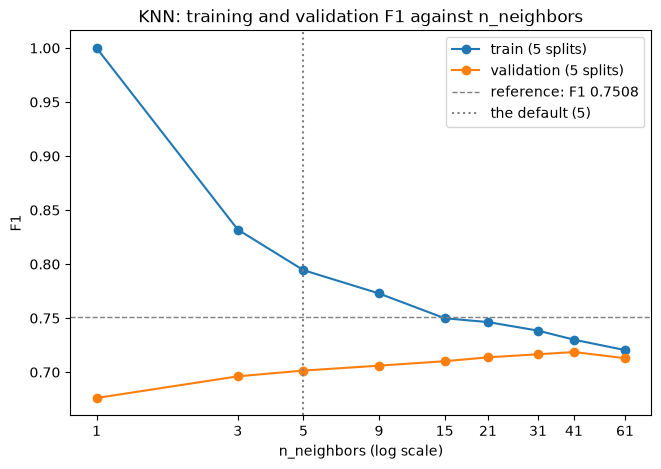

In [20]:
# training and validation F1 against n_neighbors; the gap between the lines is overfitting
plt.figure(figsize=(7.5, 5))
plt.plot(k_values, [k_runs[f"n_neighbors={value}"]["train f1"].mean() for value in k_values],
         marker="o", label="train (5 splits)")
plt.plot(k_values, [k_runs[f"n_neighbors={value}"]["f1"].mean() for value in k_values],
         marker="o", label="validation (5 splits)")
plt.axhline(reference["f1"].mean(), color="grey", linestyle="--", linewidth=1,
            label=f"reference: F1 {reference['f1'].mean():.4f}")
plt.axvline(5, color="grey", linestyle=":", linewidth=1.5, label="the default (5)")
plt.xscale("log")
plt.xticks(k_values, k_values)
plt.minorticks_off()
plt.xlabel("n_neighbors (log scale)")
plt.ylabel("F1")
plt.title("KNN: training and validation F1 against n_neighbors")
plt.legend()
plt.show()

In [21]:
weight_values = ["uniform", "distance"]
weights_table, weights_runs = sweep({f"weights={value}": KNeighborsClassifier(weights=value)
                                     for value in weight_values})
weights_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
weights=uniform,0.7015,-0.0494,0.0210,0 of 5,worse,0.7944,0.0929,0.6644,56.5863
weights=distance,0.7031,-0.0478,0.0194,0 of 5,worse,1.0000,0.2969,0.6664,56.4935


In [22]:
p_values = [1, 2, 3]
p_table, p_runs = sweep({f"p={value}": KNeighborsClassifier(p=value) for value in p_values})
p_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
p=1,0.7100,-0.0409,0.0137,0 of 5,worse,0.7955,0.0855,0.6738,56.5306
p=2,0.7015,-0.0494,0.0210,0 of 5,worse,0.7944,0.0929,0.6644,56.5863
p=3,0.6955,-0.0553,0.0219,0 of 5,worse,0.7925,0.0970,0.6579,56.3822


In [23]:
# the grid: n_neighbors x weights x p, without p=3 (the worst and the slowest)
grid_p = [1, 2]
knn_grid = {f"n_neighbors={k}, weights={w}, p={p}": KNeighborsClassifier(n_neighbors=k, weights=w, p=p)
            for k in k_values for w in weight_values for p in grid_p}
knn_grid_table, knn_grid_runs = sweep(knn_grid)

print(f"{len(knn_grid)} combinations; the 5 best by mean F1, and the default KNN:")
knn_default_name = "n_neighbors=5, weights=uniform, p=2"
knn_top = knn_grid_table.sort_values("f1", ascending=False).head(5)
knn_top = pd.concat([knn_top, knn_grid_table.loc[[knn_default_name]]])
knn_top.round(4)

36 combinations; the 5 best by mean F1, and the default KNN:


,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
"n_neighbors=41, weights=uniform, p=1",0.7293,-0.0216,0.0096,0 of 5,worse,0.7305,0.0012,0.6967,56.0668
"n_neighbors=41, weights=distance, p=1",0.7284,-0.0225,0.0105,0 of 5,worse,1.0000,0.2716,0.6965,55.8256
"n_neighbors=61, weights=distance, p=1",0.7279,-0.0229,0.0150,0 of 5,worse,1.0000,0.2721,0.6968,55.5659
"n_neighbors=21, weights=uniform, p=1",0.7269,-0.0239,0.0141,0 of 5,worse,0.7448,0.0179,0.6952,55.8813
"n_neighbors=15, weights=distance, p=1",0.7252,-0.0256,0.0128,0 of 5,worse,1.0000,0.2748,0.6928,56.1596
"n_neighbors=5, weights=uniform, p=2",0.7015,-0.0494,0.0210,0 of 5,worse,0.7944,0.0929,0.6644,56.5863


In [24]:
knn_chosen_name = knn_grid_table["f1"].idxmax()
BEST_KNN = clone(knn_grid[knn_chosen_name])   # for the threshold and the final table
knn_runs = knn_grid_runs[knn_chosen_name]
print(f"best KNN: {knn_chosen_name}")
print(knn_grid_table.loc[[knn_chosen_name]].round(4).to_string())

best KNN: n_neighbors=41, weights=uniform, p=1
                                          f1  vs base  2 x SEM better on verdict  train F1  train - validation  accuracy  % predicted 1
n_neighbors=41, weights=uniform, p=1  0.7293  -0.0216   0.0096    0 of 5   worse    0.7305              0.0012    0.6967        56.0668


## 6. Decision tree

The tree asks questions about the columns ("spend_90d <= x?") and answers with the most
frequent class of the leaf a purchase falls into. It does not need scaling or log1p, because
a transformation that keeps the order does not change the questions, but it uses the same
`prepare_selected` so that it is measured on the same ruler. Every tree gets a
`random_state`. We test eight settings one at a time: `max_depth`, `min_samples_leaf`,
`min_samples_split` and `ccp_alpha` (pruning after the tree has grown), then `splitter`,
`criterion`, `max_features` and `class_weight`. The grid uses the three that moved F1 the
most, `max_depth`, `min_samples_leaf` and `ccp_alpha`, because all eight together (256
combinations) would be too slow; `ccp_alpha=0.0001` is left out because it prunes nothing.
That leaves 5 × 4 × 3 = 60 combinations.

By default the tree memorises the training data: training F1 of 1 and validation F1 near
0.63, with depth 48 and 1247 leaves. Limiting its growth helps most: `min_samples_leaf=50`
gives 0.7299 (94 leaves) and `max_depth=2` gives 0.7275 with only 4 leaves, although there
the training F1 (0.7025) and the validation F1 are low and close, a sign of underfitting.
Pruning after growth (`ccp_alpha=0.01`) reaches the same 4-leaf tree as `max_depth=2`, and
`ccp_alpha=0.001` varies a lot between splits (2 × SEM = 0.058). The other four settings move
the unlimited tree by a few hundredths, far from what limiting its growth does, and "entropy"
and "log_loss" give the same tree. The large trees give slightly different F1 values on
different computers, because with dozens of levels small rounding differences change the
deepest splits; the small trees at the top of the grid, the chosen one and the submission
do not change.

The grid chooses `max_depth=5`, `min_samples_leaf=50`, `ccp_alpha=0.001`: F1 0.7303, −0.0206
against the reference (2 × SEM = 0.0168, better on 1 of 5), accuracy 0.7058, with 14 leaves
and 53% of purchases predicted as 1. Its training F1 (0.7151) matches the validation F1, so
it does not overfit. The 5 best combinations all score between 0.729 and 0.730, so there is
a good region rather than a single winner. No tree reaches the logistic regression: almost
all 60 combinations are worse, and the few that tie only do so because they vary a lot
between splits. It was chosen on the same splits that measure it, so its score is optimistic,
and it enters the final table as a different algorithm.

In [25]:
from sklearn.tree import DecisionTreeClassifier


def tree_size(model):
    """Depth and leaves of the tree fitted on all the training rows.

    fit_predict fits the model it receives, so after it the copy is fitted.
    """
    fitted = clone(model)
    fit_predict(prepare_selected, frame, frame, SCALER_FINAL, ENCODER_FINAL, fitted)
    return fitted.get_depth(), fitted.get_n_leaves()


def tree_sweep(setting, values):
    """One tree setting at a time, with the others at their default."""
    models = {f"{setting}={value}": DecisionTreeClassifier(random_state=RANDOM_STATE,
                                                            **{setting: value})
              for value in values}
    table, runs = sweep(models)
    table["depth"], table["leaves"] = zip(*[tree_size(m) for m in models.values()])
    return table, runs


# max_depth limits how many questions a path can ask; the default, None, lets the tree grow
max_depth_values = [2, 3, 5, 10, None]
depth_table, depth_runs = tree_sweep("max_depth", max_depth_values)
depth_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1,depth,leaves
max_depth=2,0.7275,-0.0233,0.0098,0 of 5,worse,0.7025,-0.0251,0.6870,59.0724,2,4
max_depth=3,0.7177,-0.0331,0.0135,0 of 5,worse,0.6946,-0.0232,0.6937,52.8757,3,8
max_depth=5,0.7173,-0.0335,0.0210,0 of 5,worse,0.7387,0.0214,0.6842,55.6401,5,31
max_depth=10,0.6539,-0.0969,0.0295,0 of 5,worse,0.8546,0.2007,0.6258,51.7996,10,329
max_depth=None,0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165,48,1247


In [26]:
# each leaf must keep at least this many training purchases (default 1)
leaf_values = [1, 5, 20, 50]
leaf_table, leaf_runs = tree_sweep("min_samples_leaf", leaf_values)
leaf_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1,depth,leaves
min_samples_leaf=1,0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165,48,1247
min_samples_leaf=5,0.6663,-0.0846,0.0079,0 of 5,worse,0.8789,0.2126,0.6228,56.8460,33,700
min_samples_leaf=20,0.7107,-0.0401,0.0112,0 of 5,worse,0.7826,0.0719,0.6688,58.1818,20,230
min_samples_leaf=50,0.7299,-0.0210,0.0193,0 of 5,worse,0.7360,0.0061,0.6924,57.6809,11,94


In [27]:
# a node with fewer purchases than this is not split again; it limits the parent, where
# min_samples_leaf limits the children
split_values = [2, 10, 50]
split_table, split_runs = tree_sweep("min_samples_split", split_values)
split_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1,depth,leaves
min_samples_split=2,0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165,48,1247
min_samples_split=10,0.6129,-0.1379,0.0290,0 of 5,worse,0.9278,0.3148,0.5794,52.4304,44,848
min_samples_split=50,0.6783,-0.0725,0.0129,0 of 5,worse,0.8132,0.1349,0.6404,55.4917,36,304


In [28]:
# ccp_alpha: the tree grows fully, then loses every branch that does not save at least
# ccp_alpha of impurity per leaf it adds; the default, 0.0, prunes nothing
alpha_values = [0.0, 0.0001, 0.001, 0.01]
alpha_table, alpha_runs = tree_sweep("ccp_alpha", alpha_values)
alpha_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1,depth,leaves
ccp_alpha=0.0,0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165,48,1247
ccp_alpha=0.0001,0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165,48,1247
ccp_alpha=0.001,0.6942,-0.0566,0.0578,0 of 5,tie,0.8236,0.1294,0.6638,53.7106,5,19
ccp_alpha=0.01,0.7275,-0.0233,0.0098,0 of 5,worse,0.7025,-0.0251,0.6870,59.0724,2,4


In [29]:
# the other four settings, each on its own; "entropy" and "log_loss" are the same measure
other_settings = {"splitter": ["best", "random"],
                  "criterion": ["gini", "entropy", "log_loss"],
                  "max_features": [None, "sqrt", "log2"],
                  "class_weight": [None, "balanced"]}
other_tables = {}
for setting, values in other_settings.items():
    other_tables[setting], _ = tree_sweep(setting, values)
    print(other_tables[setting][["f1", "vs base", "train F1", "accuracy", "% predicted 1",
                                 "depth", "leaves"]].round(4).to_string(), "\n")

                     f1  vs base  train F1  accuracy  % predicted 1  depth  leaves
splitter=best    0.6255  -0.1254       1.0    0.5839        54.9165     48    1247
splitter=random  0.6561  -0.0947       1.0    0.6186        54.8609     34    2033 



                        f1  vs base  train F1  accuracy  % predicted 1  depth  leaves
criterion=gini      0.6255  -0.1254       1.0    0.5839        54.9165     48    1247
criterion=entropy   0.6496  -0.1012       1.0    0.6056        56.1967     51    1200
criterion=log_loss  0.6496  -0.1012       1.0    0.6056        56.1967     51    1200 



                       f1  vs base  train F1  accuracy  % predicted 1  depth  leaves
max_features=None  0.6255  -0.1254       1.0    0.5839        54.9165     48    1247
max_features=sqrt  0.6630  -0.0878       1.0    0.6245        55.4174     40    1882
max_features=log2  0.6634  -0.0875       1.0    0.6243        55.6586     40    2019 



                           f1  vs base  train F1  accuracy  % predicted 1  depth  leaves
class_weight=None      0.6255  -0.1254       1.0    0.5839        54.9165     48    1247
class_weight=balanced  0.6361  -0.1148       1.0    0.5926        55.7143     48    1418 



In [30]:
# two ways to prune: the best value of each setting that limits growth, and of ccp_alpha,
# beside the default tree
pruning_rows = []
for kind, table in [("none (default)", depth_table.loc[["max_depth=None"]]),
                    ("before growing", depth_table), ("before growing", leaf_table),
                    ("before growing", split_table), ("after growing", alpha_table)]:
    best = table["f1"].idxmax()
    pruning_rows.append({"pruning": kind, "tree": best,
                         **table.loc[best, ["depth", "leaves", "f1", "train F1",
                                            "accuracy", "vs base", "verdict"]].to_dict()})
pruning_table = pd.DataFrame(pruning_rows).set_index("tree")
pruning_table.round(4)

,pruning,depth,leaves,f1,train F1,accuracy,vs base,verdict
tree,,,,,,,,
max_depth=None,none (default),48,1247,0.6255,1.0000,0.5839,-0.1254,worse
max_depth=2,before growing,2,4,0.7275,0.7025,0.6870,-0.0233,worse
min_samples_leaf=50,before growing,11,94,0.7299,0.7360,0.6924,-0.0210,worse
min_samples_split=50,before growing,36,304,0.6783,0.8132,0.6404,-0.0725,worse
ccp_alpha=0.01,after growing,2,4,0.7275,0.7025,0.6870,-0.0233,worse


In [31]:
# the grid with the three settings that moved F1 the most
tree_grid = {f"max_depth={d}, min_samples_leaf={leaf}, ccp_alpha={alpha}":
             DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, ccp_alpha=alpha,
                                    random_state=RANDOM_STATE)
             for d in max_depth_values for leaf in leaf_values for alpha in [0.0, 0.001, 0.01]}
tree_grid_table, tree_grid_runs = sweep(tree_grid)

print(f"{len(tree_grid)} combinations; the 5 best by mean F1, and the default tree:")
tree_default_name = "max_depth=None, min_samples_leaf=1, ccp_alpha=0.0"
tree_top = tree_grid_table.sort_values("f1", ascending=False).head(5)
tree_top = pd.concat([tree_top, tree_grid_table.loc[[tree_default_name]]])
tree_top.round(4)

60 combinations; the 5 best by mean F1, and the default tree:


,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
"max_depth=5, min_samples_leaf=50, ccp_alpha=0.001",0.7303,-0.0206,0.0168,1 of 5,worse,0.7151,-0.0152,0.7058,53.1911
"max_depth=10, min_samples_leaf=50, ccp_alpha=0.0",0.7299,-0.0210,0.0193,0 of 5,worse,0.7360,0.0061,0.6924,57.6809
"max_depth=None, min_samples_leaf=50, ccp_alpha=0.0",0.7299,-0.0210,0.0193,0 of 5,worse,0.7360,0.0061,0.6924,57.6809
"max_depth=5, min_samples_leaf=50, ccp_alpha=0.0",0.7298,-0.0210,0.0190,1 of 5,worse,0.7222,-0.0076,0.6950,56.7532
"max_depth=None, min_samples_leaf=50, ccp_alpha=0.001",0.7289,-0.0220,0.0177,1 of 5,worse,0.7196,-0.0093,0.7050,52.9685
"max_depth=None, min_samples_leaf=1, ccp_alpha=0.0",0.6255,-0.1254,0.0244,0 of 5,worse,1.0000,0.3745,0.5839,54.9165


In [32]:
tree_chosen_name = tree_grid_table["f1"].idxmax()
BEST_TREE = clone(tree_grid[tree_chosen_name])   # for the threshold and the final table
tree_runs = tree_grid_runs[tree_chosen_name]
print(f"best tree: {tree_chosen_name}, with {tree_size(BEST_TREE)[1]} leaves on the full training set")
print(tree_grid_table.loc[[tree_chosen_name]].round(4).to_string())

best tree: max_depth=5, min_samples_leaf=50, ccp_alpha=0.001, with 14 leaves on the full training set
                                                       f1  vs base  2 x SEM better on verdict  train F1  train - validation  accuracy  % predicted 1
max_depth=5, min_samples_leaf=50, ccp_alpha=0.001  0.7303  -0.0206   0.0168    1 of 5   worse    0.7151             -0.0152    0.7058        53.1911


## 7. Decision threshold

All four models give a probability of class 1, and `predict` says 1 when it reaches 0.5. To
choose another threshold we pool the validation probabilities of the 5 splits (each model
trains on the past and scores the purchases that come next) and give each model one
threshold, the one that would be applied to `test.csv`. We take the threshold with the
highest F1 on the precision-recall curve, since F1 is our metric and Kaggle's, and show the
Youden index on the ROC curve beside it. Each model is then measured with its threshold
against the same model at 0.5, split by split, with accuracy and the share of 1s beside,
because lowering the threshold makes the model say 1 more often, and that almost always
raises F1.

On the precision-recall curve the logistic regression gets 0.44, KNN 0.37 and the tree 0.38.
All three lower the threshold and predict more 1s (64%, 79% and 71%, against 53% to 57% at
0.5). Naive Bayes is the only one that raises it (0.57), because at 0.5 it already predicted
1 for 89% of purchases. The Youden index raises the threshold for all four and lowers F1,
because it counts both errors equally instead of maximising F1. Split by split, no threshold
passes 2 × SEM in F1: all of them tie with 0.5 (logistic regression +0.0039, 2 × SEM =
0.0064). In accuracy the logistic regression, KNN and the tree get worse, and only Naive
Bayes improves, because it stops predicting 1 almost every time. The pooled F1 (0.7550 at
0.5) is not the mean of the 5 splits (0.7540); the mean per split is the one we compare.
The thresholds were chosen on the same validation rows that measure them, so even these
small gains are optimistic.

With the 2 × SEM rule no threshold is a proven improvement, so 0.5 stays for all four
models here. The final table shows each model with and without its threshold.

In [33]:
from sklearn.metrics import precision_recall_curve, roc_curve

best_models = {"logistic regression": BEST_LOGISTIC, "Naive Bayes": BEST_NAIVE_BAYES,
               "KNN": BEST_KNN, "decision tree": BEST_TREE}


def pooled_probabilities(model):
    """The class 1 probabilities on the 5 validation sets, pooled, and the true target."""
    probabilities, truth = [], []
    for train_idx, val_idx in splits:
        train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
        probabilities.append(fit_predict(prepare_selected, train, valid, SCALER_FINAL,
                                         ENCODER_FINAL, model, proba=True))
        truth.append(valid[TARGET].to_numpy())
    return np.concatenate(probabilities), np.concatenate(truth)


pooled = {name: pooled_probabilities(model) for name, model in best_models.items()}
for name, (probability, truth) in pooled.items():
    print(f"{name}: {len(probability):,} probabilities, {len(np.unique(probability)):,} distinct"
          f" values, from {probability.min():.4f} to {probability.max():.4f}")

logistic regression: 5,390 probabilities, 5,390 distinct values, from 0.0014 to 0.9984
Naive Bayes: 5,390 probabilities, 5,390 distinct values, from 0.2688 to 0.9912
KNN: 5,390 probabilities, 41 distinct values, from 0.0244 to 1.0000
decision tree: 5,390 probabilities, 72 distinct values, from 0.1094 to 0.9897


In [34]:
def metrics_at(probability, truth, threshold):
    """The metrics of the labels a threshold gives, plus the % of predictions equal to 1."""
    labels = (probability >= threshold).astype(int)
    return {"threshold": threshold, "accuracy": accuracy_score(truth, labels),
            "precision": precision_score(truth, labels, zero_division=0),
            "recall": recall_score(truth, labels), "F1": f1_score(truth, labels, zero_division=0),
            "% predicted 1": 100 * labels.mean()}


chosen_thresholds, method_rows = {}, []
for name, (probability, truth) in pooled.items():
    # the F1 of every threshold on the precision-recall curve, and the highest
    precision, recall, thresholds_pr = precision_recall_curve(truth, probability)
    f1_scores = np.where((precision + recall) == 0, 0,
                         2 * (precision * recall) / (precision + recall))
    optimal_threshold_pr = thresholds_pr[np.argmax(f1_scores)]
    # the Youden index (TPR - FPR) on the ROC curve
    fpr, tpr, thresholds = roc_curve(truth, probability)
    optimal_threshold_roc = thresholds[np.argmax(tpr - fpr)]
    chosen_thresholds[name] = float(optimal_threshold_pr)
    for method, threshold in [("default", 0.5), ("ROC (Youden)", optimal_threshold_roc),
                              ("PR (max F1)", optimal_threshold_pr)]:
        method_rows.append({"model": name, "method": method,
                            **metrics_at(probability, truth, threshold)})
pd.DataFrame(method_rows).set_index(["model", "method"]).round(4)

threshold  accuracy  precision  recall  \
model               method                                                 
logistic regression default          0.5000    0.7219     0.7500  0.7601   
                    ROC (Youden)     0.5589    0.7208     0.7803  0.7025   
                    PR (max F1)      0.4398    0.7104     0.7155  0.8075   
Naive Bayes         default          0.5000    0.6212     0.6039  0.9533   
                    ROC (Youden)     0.8175    0.6733     0.7667  0.6045   
                    PR (max F1)      0.5651    0.6481     0.6284  0.9197   
KNN                 default          0.5000    0.6967     0.7323  0.7282   
                    ROC (Youden)     0.6341    0.6833     0.8124  0.5699   
                    PR (max F1)      0.3659    0.6540     0.6379  0.8937   
decision tree       default          0.5000    0.7035     0.7423  0.7262   
                    ROC (Youden)     0.6073    0.7028     0.7808  0.6575   
                    PR (max F1)      0.3797    0.6711     0.6651  0.8391   

                                      F1  % predicted 1  
model               method                               
logistic regression default       0.7550        57.1429  
                    ROC (Youden)  0.7394        50.7607  
                    PR (max F1)   0.7587        63.6364  
Naive Bayes         default       0.7394        88.9981  
                    ROC (Youden)  0.6760        44.4527  
                    PR (max F1)   0.7466        82.5232  
KNN                 default       0.7302        56.0668  
                    ROC (Youden)  0.6699        39.5547  
                    PR (max F1)   0.7444        78.9981  
decision tree       default       0.7342        55.1577  
                    ROC (Youden)  0.7138        47.4768  
                    PR (max F1)   0.7420        71.1317

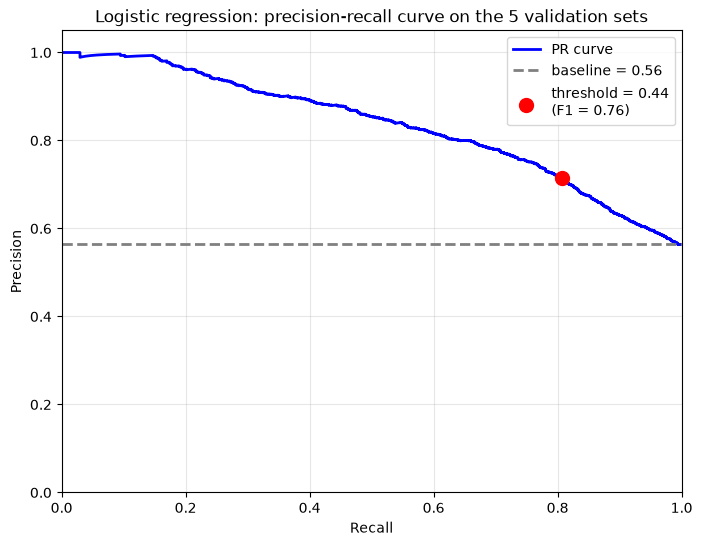

In [35]:
# the precision-recall curve of the logistic regression, the baseline (share of repeat
# purchases) and the point with the highest F1
probability, truth = pooled["logistic regression"]
precision, recall, thresholds_pr = precision_recall_curve(truth, probability)
f1_scores = np.where((precision + recall) == 0, 0, 2 * (precision * recall) / (precision + recall))
optimal_idx_pr = np.argmax(f1_scores)
baseline = truth.sum() / len(truth)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color="blue", lw=2, label="PR curve")
plt.axhline(y=baseline, color="gray", linestyle="--", lw=2, label=f"baseline = {baseline:.2f}")
plt.scatter(recall[optimal_idx_pr], precision[optimal_idx_pr], color="red", s=100, zorder=5,
            label=f"threshold = {thresholds_pr[optimal_idx_pr]:.2f}\n(F1 = {f1_scores[optimal_idx_pr]:.2f})")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic regression: precision-recall curve on the 5 validation sets")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.show()

In [36]:
# each model with its threshold against the same model at 0.5; the 0.5 results already exist
model_runs = {"logistic regression": logistic_runs, "Naive Bayes": naive_bayes_runs,
              "KNN": knn_runs, "decision tree": tree_runs}
threshold_rows = []
threshold_runs = {}
for name, model in best_models.items():
    at_05 = model_runs[name]
    at_chosen = run_model(model, chosen_thresholds[name])
    threshold_runs[name] = at_chosen
    for metric in ["f1", "accuracy"]:
        diff = compare({name: at_chosen}, at_05, metric=metric).astype({"vs base": float,
                                                                         "SEM": float})
        diff["verdict"] = verdict(diff)
        threshold_rows.append({"model": name, "metric": metric,
                               "0.5": at_05[metric].mean(),
                               "threshold": chosen_thresholds[name],
                               "with threshold": at_chosen[metric].mean(),
                               "difference": diff["vs base"].iloc[0],
                               "2 x SEM": 2 * diff["SEM"].iloc[0],
                               "better on": diff["better on"].iloc[0],
                               "verdict": diff["verdict"].iloc[0],
                               "% predicted 1 (0.5)": at_05["% predicted 1"].mean(),
                               "% predicted 1 (threshold)": at_chosen["% predicted 1"].mean()})
pd.DataFrame(threshold_rows).set_index(["model", "metric"]).round(4)

0.5  threshold  with threshold  difference  \
model               metric                                                    
logistic regression f1        0.7540     0.4398          0.7579      0.0039   
                    accuracy  0.7219     0.4398          0.7104     -0.0115   
Naive Bayes         f1        0.7390     0.5651          0.7461      0.0071   
                    accuracy  0.6212     0.5651          0.6481      0.0269   
KNN                 f1        0.7293     0.3659          0.7435      0.0143   
                    accuracy  0.6967     0.3659          0.6540     -0.0427   
decision tree       f1        0.7303     0.3797          0.7413      0.0111   
                    accuracy  0.7058     0.3797          0.6711     -0.0347   

                              2 x SEM better on verdict  % predicted 1 (0.5)  \
model               metric                                                     
logistic regression f1         0.0064    4 of 5     tie              57.1429   
                    accuracy   0.0084    0 of 5   worse              57.1429   
Naive Bayes         f1         0.0085    4 of 5     tie              88.9981   
                    accuracy   0.0155    5 of 5  better              88.9981   
KNN                 f1         0.0156    4 of 5     tie              56.0668   
                    accuracy   0.0217    0 of 5   worse              56.0668   
decision tree       f1         0.0114    4 of 5     tie              53.1911   
                    accuracy   0.0211    0 of 5   worse              53.1911   

                              % predicted 1 (threshold)  
model               metric                               
logistic regression f1                          63.6364  
                    accuracy                    63.6364  
Naive Bayes         f1                          82.5232  
                    accuracy                    82.5232  
KNN                 f1                          78.9981  
                    accuracy                    78.9981  
decision tree       f1                          71.1317  
                    accuracy                    71.1317

In [37]:
print("precision-recall thresholds, for the final table:", {name: round(value, 4)
                                                           for name, value in chosen_thresholds.items()})

precision-recall thresholds, for the final table: {'logistic regression': 0.4398, 'Naive Bayes': 0.5651, 'KNN': 0.3659, 'decision tree': 0.3797}


## 8. Final model

The final table puts the best model of each algorithm side by side, with the 0.5 threshold
and with its precision-recall threshold, against the reference on the same 5 splits. Nothing
is trained again: the split results come from the sections above. The choice follows three
rules. Only the rows better than the reference count (if none is, the reference stays); among
them the one with the highest mean F1 wins; and if another one ties with it split by split,
the simpler one stays. Simpler means without a threshold (the model's own `predict`, one
choice fewer) and, between algorithms, the order logistic regression, Naive Bayes, KNN, tree.

Only two rows beat the reference, both of them logistic regression. The one with the highest
F1 uses the 0.44 threshold (+0.0070), but it ties with the same model at 0.5 and predicts 1
for 64% of purchases with lower accuracy, so the rule picks 0.5. The other three algorithms
tie with the reference or lose to it, with or without a threshold. All the models were chosen
on the same splits that measure them, so their scores are optimistic; nested cross-validation
is left for the project.


In [38]:
# the best model of each algorithm, at 0.5 and at its precision-recall threshold
final_runs = {"reference (default logistic regression)": reference}
for name, runs in model_runs.items():
    final_runs[f"{name}, threshold 0.5"] = runs
    final_runs[f"{name}, threshold {chosen_thresholds[name]:.2f}"] = threshold_runs[name]

# the same columns as sweep
final_table = compare(final_runs, reference, metric="f1").astype(
    {"f1": float, "accuracy": float, "vs base": float, "SEM": float})
final_table["2 x SEM"] = 2 * final_table["SEM"]
final_table["verdict"] = verdict(final_table)
final_table["train F1"] = [final_runs[name]["train f1"].mean() for name in final_table.index]
final_table["train - validation"] = final_table["train F1"] - final_table["f1"]
final_table["% predicted 1"] = [final_runs[name]["% predicted 1"].mean() for name in final_table.index]
final_table = final_table[["f1", "vs base", "2 x SEM", "better on", "verdict", "train F1",
                           "train - validation", "accuracy", "% predicted 1"]]
final_table.round(4)

,f1,vs base,2 x SEM,better on,verdict,train F1,train - validation,accuracy,% predicted 1
reference (default logistic regression),0.7508,0.0000,0.0000,0 of 5,tie,0.7316,-0.0192,0.7163,57.8850
"logistic regression, threshold 0.5",0.7540,0.0031,0.0028,5 of 5,better,0.7309,-0.0231,0.7219,57.1429
"logistic regression, threshold 0.44",0.7579,0.0070,0.0051,5 of 5,better,0.7437,-0.0142,0.7104,63.6364
"Naive Bayes, threshold 0.5",0.7390,-0.0119,0.0163,1 of 5,tie,0.7175,-0.0215,0.6212,88.9981
"Naive Bayes, threshold 0.57",0.7461,-0.0047,0.0136,1 of 5,tie,0.7130,-0.0332,0.6481,82.5232
"KNN, threshold 0.5",0.7293,-0.0216,0.0096,0 of 5,worse,0.7305,0.0012,0.6967,56.0668
"KNN, threshold 0.37",0.7435,-0.0073,0.0136,1 of 5,tie,0.7500,0.0065,0.6540,78.9981
"decision tree, threshold 0.5",0.7303,-0.0206,0.0168,1 of 5,worse,0.7151,-0.0152,0.7058,53.1911
"decision tree, threshold 0.38",0.7413,-0.0095,0.0107,1 of 5,tie,0.7464,0.0051,0.6711,71.1317


In [39]:
better = final_table[final_table["verdict"] == "better"]
if better.empty:
    final_name = "reference"
else:
    top_name = better["f1"].idxmax()
    ties = compare({name: final_runs[name] for name in better.index}, final_runs[top_name])
    ties = ties.astype({"f1": float, "vs base": float, "SEM": float})
    ties["2 x SEM"] = 2 * ties["SEM"]
    ties["verdict"] = verdict(ties)
    print(f"{len(better)} rows better than the reference; the highest F1: {top_name}")
    print(ties[["f1", "vs base", "2 x SEM", "better on", "verdict"]].round(4).to_string())
    simplest_first = ([f"{name}, threshold 0.5" for name in model_runs]
                      + [f"{name}, threshold {chosen_thresholds[name]:.2f}" for name in model_runs])
    final_name = next(name for name in simplest_first
                      if name in ties.index and ties.loc[name, "verdict"] != "worse")
print(f"\nfinal model by the rule: {final_name}")

2 rows better than the reference; the highest F1: logistic regression, threshold 0.44
                                         f1  vs base  2 x SEM better on verdict
logistic regression, threshold 0.5   0.7540  -0.0039   0.0064    1 of 5     tie
logistic regression, threshold 0.44  0.7579   0.0000   0.0000    0 of 5     tie

final model by the rule: logistic regression, threshold 0.5


### Without the 90-day overlap

The target of a purchase looks 90 days ahead. In the splits above, the last training purchases
of each split are less than 90 days before validation starts, so their targets already depend
on what happens during the validation period. Here each training part stops 90 days before its
validation starts, so no training target can see into validation.

Without the overlap, the L1 logistic regression no longer beats the reference, with or without
its precision-recall threshold: both tie. With a tie, the rule keeps the simpler model, so the
final model is the default logistic regression with the 0.5 threshold. It is written by hand
below (`LogisticRegression(max_iter=1000)` with a `random_state`, the model every section used
as the reference) and gives the predictions of Version04, submitted as Version08.

In [40]:
# each training part stops 90 days before its validation starts
dates = pd.to_datetime(frame[DATE]).to_numpy()
purged_splits = []
for train_idx, val_idx in splits:
    cut = dates[val_idx].min() - np.timedelta64(90, "D")
    purged_splits.append((train_idx[dates[train_idx] <= cut], val_idx))
print("training purchases per split, with and without the overlap:",
      [len(t) for t, _ in splits], [len(t) for t, _ in purged_splits])


def run_purged(model, threshold=None):
    """Validation F1, accuracy and % of 1s on the splits without the overlap."""
    rows = []
    for train_idx, val_idx in purged_splits:
        valid = frame.iloc[val_idx]
        predicted = fit_predict(prepare_selected, frame.iloc[train_idx], valid, SCALER_FINAL,
                                ENCODER_FINAL, model, None, threshold)
        rows.append({"f1": f1_score(valid[TARGET], predicted),
                     "accuracy": accuracy_score(valid[TARGET], predicted),
                     "% predicted 1": 100 * predicted.mean()})
    return pd.DataFrame(rows)


purged_reference = run_purged(None)
logistic_threshold_value = chosen_thresholds["logistic regression"]
purged_runs = {
    "logistic regression, threshold 0.5": run_purged(clone(BEST_LOGISTIC)),
    f"logistic regression, threshold {logistic_threshold_value:.2f}":
        run_purged(clone(BEST_LOGISTIC), logistic_threshold_value),
}
purged_table = compare(purged_runs, purged_reference).astype(
    {"f1": float, "accuracy": float, "vs base": float, "SEM": float})
purged_table["2 x SEM"] = 2 * purged_table["SEM"]
purged_table["verdict"] = verdict(purged_table)
purged_table["% predicted 1"] = [purged_runs[name]["% predicted 1"].mean()
                                 for name in purged_table.index]
print(f"reference without the overlap: F1 {purged_reference['f1'].mean():.4f},"
      f" accuracy {purged_reference['accuracy'].mean():.4f}\n")
print(purged_table[["f1", "vs base", "2 x SEM", "better on", "verdict", "accuracy",
                    "% predicted 1"]].round(4).to_string())

training purchases per split, with and without the overlap: [1079, 2157, 3235, 4313, 5391] [942, 1923, 3109, 4190, 5208]


reference without the overlap: F1 0.7483, accuracy 0.7176

                                         f1  vs base  2 x SEM better on verdict  accuracy  % predicted 1
logistic regression, threshold 0.5   0.7461  -0.0021    0.004    2 of 5     tie    0.7171        55.1763
logistic regression, threshold 0.44  0.7522   0.0039    0.009    3 of 5     tie    0.7069        62.0594


In [41]:
FINAL_MODEL = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
FINAL_THRESHOLD = None   # the model's own predict (threshold 0.5)

if (purged_table["verdict"] == "better").any():
    print("warning: on this computer a row beats the reference without the overlap;"
          " the final model is still the one written by hand")
final_run = run_model(FINAL_MODEL, FINAL_THRESHOLD)
print(f"final model: F1 {final_run['f1'].mean():.4f} +- {sem(final_run['f1']):.4f},"
      f" accuracy {final_run['accuracy'].mean():.4f}, predicts 1 for"
      f" {final_run['% predicted 1'].mean():.1f}% of purchases")

final model: F1 0.7508 +- 0.0074, accuracy 0.7163, predicts 1 for 57.9% of purchases


## 9. Decision table

What this notebook tested and decided, one row per section, as in the decision tables of the
preprocessing notebook. The numbers come from the cells above, so they change with them.

In [42]:
def best(table, name):
    """F1, difference against the reference and verdict of one row of a sweep table."""
    row = table.loc[name]
    return f"F1 {row['f1']:.4f} ({row['vs base']:+.4f}, {row['verdict']})"


logistic_threshold = next(row for row in threshold_rows
                          if row["model"] == "logistic regression" and row["metric"] == "f1")
nb_row = nb_grid_table.loc[nb_chosen_name]
decisions = pd.DataFrame([
    ("1. Reference", "model ruler: run_model and sweep",
     f"reference (default logistic regression): F1 {reference['f1'].mean():.4f},"
     f" accuracy {reference['accuracy'].mean():.4f}",
     "every model is measured against it, on the same 5 splits"),
    ("2. Strategy and metric", "evaluation strategy and metric",
     "time-based cross-validation (TimeSeriesSplit, 5 splits); always predicting 1 gives F1 0.721",
     "F1 decides (it is the Kaggle metric); accuracy, precision and recall beside it"),
    ("3. Logistic regression", f"logistic regression: C, L1/L2/elastic net, class_weight, fit_intercept;"
            f" grid of {len(grid)}",
     f"{logistic_chosen_name}: {best(grid_table, logistic_chosen_name)}",
     "better on these splits, but it ties without the 90-day overlap (section 8)"),
    ("4. Naive Bayes", f"Naive Bayes: var_smoothing, priors, calibration; grid of {len(nb_grid)}",
     f"{best(nb_grid_table, nb_chosen_name)}, but it predicts 1 for {nb_row['% predicted 1']:.0f}% and"
     f" accuracy falls to {nb_row['accuracy']:.4f}",
     "not kept: it only gains F1 by predicting more 1s"),
    ("5. KNN", f"KNN: n_neighbors, weights, p; grid of {len(knn_grid)}",
     f"{knn_chosen_name}: {best(knn_grid_table, knn_chosen_name)}",
     "not kept: every combination below the reference"),
    ("6. Decision tree", f"decision tree: depth, leaves, pruning and 4 other settings;"
            f" grid of {len(tree_grid)}",
     f"{tree_chosen_name}: {best(tree_grid_table, tree_chosen_name)}",
     "not kept: unlimited it memorises the training data; limited it stays below"),
    ("7. Decision threshold", "threshold: precision-recall curve (max F1) and Youden index, for the 4 models",
     f"logistic regression at {logistic_threshold['threshold']:.2f}:"
     f" {logistic_threshold['difference']:+.4f} against 0.5 ({logistic_threshold['verdict']})",
     "no threshold passes 2 x SEM; 0.5 stays"),
    ("8. Final model", "final model: the 2 x SEM rule, then the same check without the 90-day overlap",
     f"F1 {final_run['f1'].mean():.4f}, accuracy {final_run['accuracy'].mean():.4f}"
     f" (reference: F1 {reference['f1'].mean():.4f})",
     "default logistic regression, threshold 0.5: Version08 (same predictions as Version04)"),
], columns=["section", "what was tested", "result", "decision"])
print(decisions.to_string(index=False))

               section                                                                    what was tested                                                                                      result                                                                              decision
          1. Reference                                                   model ruler: run_model and sweep                         reference (default logistic regression): F1 0.7508, accuracy 0.7163                              every model is measured against it, on the same 5 splits
2. Strategy and metric                                                     evaluation strategy and metric time-based cross-validation (TimeSeriesSplit, 5 splits); always predicting 1 gives F1 0.721        F1 decides (it is the Kaggle metric); accuracy, precision and recall beside it
3. Logistic regression logistic regression: C, L1/L2/elastic net, class_weight, fit_intercept; grid of 24              L1, C=100, class_weight=None,

## 10. Kaggle submission

This part applies the pipeline to `test.csv` and writes the submission selected on Kaggle,
Version08, with the final model of section 8 (the same predictions as Version04). First, a check that the preparation did not
change when the submission moved here from the preprocessing notebook: without a threshold,
the final preparation and the default logistic regression, fitted on the whole training set,
give Version04 again (up to 2 different predictions are rounding on another computer).

`VERSION` and the threshold are written by hand, so running the notebook again produces the
same file. A file that already exists is never rewritten with other predictions: changing the
model or the threshold without changing `VERSION` stops the cell.

Public Kaggle scores (70% of the test set): Version04 0.79057, Version05 0.79093, Version06
0.78328. They are recorded only; the final model was chosen on the validation splits.

In [43]:
version_04 = pd.read_csv("../submissions/ML_Group_37_Version04.csv", index_col="ID")[TARGET]
same_as_04 = fit_predict(prepare_selected, frame, test_csv, SCALER_FINAL, ENCODER_FINAL)
# up to 2 different predictions are rounding on another computer; more is another pipeline
different_04 = int((same_as_04 != version_04.loc[test_csv.index].to_numpy()).sum())
assert different_04 <= 2, f"{different_04} predictions different from Version04"
print(f"without a threshold, this notebook reproduces Version04: {len(same_as_04) - different_04} of"
      f" {len(same_as_04)} predictions equal")

without a threshold, this notebook reproduces Version04: 986 of 986 predictions equal


In [44]:
TEAM = "ML_Group_37"
VERSION = 8   # the same predictions as Version04, submitted as the final version
THRESHOLD = FINAL_THRESHOLD   # None: threshold 0.5

predictions = fit_predict(prepare_selected, frame, test_csv, SCALER_FINAL, ENCODER_FINAL,
                          model=FINAL_MODEL, threshold=THRESHOLD)
submission = pd.DataFrame({"ID": test_csv.index, TARGET: predictions})

path = f"../submissions/{TEAM}_Version{VERSION:02d}.csv"
# an existing file is never rewritten with other predictions; up to 2 differences are rounding
try:
    previous = pd.read_csv(path)[TARGET].to_numpy()
except FileNotFoundError:
    previous = None
if previous is None:
    submission.to_csv(path, index=False)   # without the pandas index, as the Kaggle guide asks
else:
    changed = int((previous != predictions).sum())
    assert changed <= 2, f"{path} already exists with {changed} different predictions: change VERSION"
    print(f"{path} already exists, with {changed} different predictions on this computer:"
          " not rewritten")

sample = pd.read_csv("../data/sample_submission.csv")
print(f"file: {path}")
print(f"rows: {len(submission)}, unique IDs: {submission['ID'].nunique()},"
      f" same IDs as sample_submission: {submission['ID'].isin(sample['ID']).all()}")
print("predictions:", submission[TARGET].value_counts().sort_index().to_dict())
print("different from Version04:", int((predictions != same_as_04).sum()), "of", len(predictions))
for other in [5, 6, 7]:
    version = pd.read_csv(f"../submissions/ML_Group_37_Version{other:02d}.csv", index_col="ID")[TARGET]
    print(f"different from Version{other:02d}:",
          int((predictions != version.loc[test_csv.index].to_numpy()).sum()), "of", len(predictions))

file: ../submissions/ML_Group_37_Version08.csv
rows: 986, unique IDs: 986, same IDs as sample_submission: True
predictions: {0: 337, 1: 649}
different from Version04: 0 of 986
different from Version05: 48 of 986
different from Version06: 11 of 986
different from Version07: 57 of 986
